# Storm maps: metamodel and dynamic runs against the buoys

The largest storms of the dynamic year (08), with every estimate side by side:

- the **metamodel** (linear sum of the goal metamodels, bulk and spectral);
- the **dynamic runs** of `dynamic_runs`: the SnapWave run of 08 and, optionally, others
  over some of the same hours (another SnapWave build, SWAN).

Sections: 3 scores them against the **buoys** through each storm (the reference here), 4 maps
them at the storm hour, 5 compares the dynamic runs with one of them (`reference_run`, e.g.
SWAN) on the hours and sites they share.

Storms are the peaks of the goal-mean offshore Hs, at least `min_gap` apart, kept when the
first dynamic run saved a map (`save_map`) within `max_lag` of the peak. SnapWave clips the
boundary spread at 55° (notebook 08), the reconstruction does not: in broad-spread hours the
buoys are the referee. `tm01` only exists for the buoys and the metamodel (a stat of the
summed spectrum).

**Prerequisites:** dynamic runs postprocessed (08, `Dynamic_Cases_<period>.nc`), fitted models
(06), buoy files (03). The reconstructions are read from the cache (`tmp/reconstruct/`, filled
by 09 or a script); anything missing is computed here.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from utils import metamodel as mm
from utils import simulation as sim
from utils import validation as val
from utils import viz
from utils.config import get_offshore_wave, open_offshore_waves, resolve

## Configuration

In [ ]:
period = "2018"  # a year of the dynamic run
offshore_name = "WHACS_cal"
wind = False  # dynamic run with or without wind (08); the metamodel has none
mda_n = 800  # must match a fitted mda_candidates entry
map_set = "isobaths"  # metamodel set on the maps
buoy_set = "buoys"  # metamodel set at the buoys
wl = "forcing"  # same water level as the dynamic run
n_storms = 4
min_gap = "4D"  # least time between two storm peaks
max_lag = "6h"  # saved map at most this far from the peak
window = pd.Timedelta("3D")  # half-width of the buoy window
extent = None  # (lon_min, lon_max, lat_min, lat_max) to zoom the maps; None = the mesh
series_variables = ["hs", "tp", "tm01", "dir"]  # buoy time series
compare_variables = ["hs", "tp", "dir"]  # metrics tables

cases = sim.cases_dir("dynamic", offshore=offshore_name, wind=wind)
# Dynamic runs: label -> Dynamic_Cases file (its maps in the case folders next to it). The first
# is the run of 08 and picks the storms; the others may cover only some hours. Missing files
# are skipped.
dynamic_runs = {
    "SnapWave wind2": cases / f"Dynamic_Cases_{period}.nc",
    "SnapWave wind1": resolve(
        "SnapWave_CASES_Dynamic_WHACS_cal_wind-off_wind1-gita2018/Dynamic_Cases_gita2018.nc"
    ),
    "SWAN": resolve("SWAN_CASES_Dynamic_WHACS_cal_wind-off/Dynamic_Cases_gita2018.nc"),
}  # wind1 and SWAN: Cyclone Gita only (numerical_tests/scripts/06_swan_storm.py)
reference_run = (
    "SWAN"  # label of dynamic_runs the others are compared with in section 5
)
print(f"dynamic runs: {dynamic_runs}")

dynamic runs: {'SnapWave wind2': PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Samoa/SnapWave_CASES_Dynamic_WHACS_cal_wind-off/Dynamic_Cases_2018.nc'), 'SnapWave wind1': PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Samoa/SnapWave_CASES_Dynamic_WHACS_cal_wind-off_wind1-gita2018/Dynamic_Cases_gita2018.nc'), 'SWAN': PosixPath('/lustre/geocean/WORK/users/javiert/projects/HyGloW/Samoa/SWAN_CASES_Dynamic_WHACS_cal_wind-off/Dynamic_Cases_gita2018.nc')}


## 1 · Storms with a saved map

In [ ]:
first = next(iter(dynamic_runs))
offshore = (
    open_offshore_waves(entry=get_offshore_wave(offshore_name)).sel(time=period).load()
)
storms = val.storm_peaks(
    offshore,
    n_storms,
    min_gap=min_gap,
    max_lag=max_lag,
    map_hours=sim.saved_map_hours(Path(dynamic_runs[first]).parent),
)
storms.round(2)

,peak,goal_mean_hs,goal_max_hs,map_hour
0,2018-02-09 19:00:00,5.85,7.05,2018-02-09 21:00:00
1,2018-10-20 18:00:00,3.35,4.09,2018-10-20 18:00:00
2,2018-07-09 09:00:00,3.12,3.55,2018-07-09 03:00:00
3,2018-09-17 21:00:00,3.05,3.39,2018-09-17 22:00:00


## 2 · Metamodel, dynamic runs and buoys

In [ ]:
# Resources for the reconstructions (at most 75% of this machine). Edit res if wanted.
res = mm.reconstruction_resources(
    period,
    mda_n,
    metamodel=map_set,
    spectral=True,
    offshore_name=offshore_name,
    save_spectra=False,
    wl=wl,
)

Machine   48 cores, 388 GiB free of 503 GiB, no GPU -> at most 36 cores, 291 GiB (75%)
Request   isobaths n=800 spectral (64 contributions/site), '2018': 0 of 17208 site-months to compute, in 0 month(s)
Proposed  device cpu, 36 threads (GP + PCA), 36 workers (spectral sum), 1 month(s) x every site per call, 291 GiB
Spectra   not saved (save_spectra=True to keep them): ~0.0 GB on disk for these site-months, 6635 GB free
Edit the fields if wanted (res.workers = ...), then reconstruct(..., resources=res).


In [ ]:
paths = {
    label: Path(path) for label, path in dynamic_runs.items() if Path(path).is_file()
}
primary = xr.open_dataset(paths[first]).sel(time=period).load()
runs = {
    label: val.on_sites_of(xr.open_dataset(path).load(), primary)
    for label, path in paths.items()
}
run_maps = {label: sim.saved_map_hours(path.parent) for label, path in paths.items()}


def metamodel(spectral: bool) -> xr.Dataset:
    parts = [
        mm.reconstruct(
            period,
            mda_n,
            metamodel=s,
            spectral=spectral,
            offshore_name=offshore_name,
            resources=res,
            save_spectra=False,
            wl=wl,
        )
        for s in (map_set, buoy_set)
    ]
    both = xr.concat(parts, "sites", coords="minimal", compat="override")
    return val.on_sites_of(
        both.isel(sites=~both.get_index("sites").duplicated()), primary
    )


estimates = {
    "Metamodel bulk": metamodel(False),
    "Metamodel spectral": metamodel(True),
} | runs
buoy = val.on_sites_of(
    val.load_buoy_observations(period, variables=series_variables), primary
)
for label, est in estimates.items():
    print(
        f"{label:20s} {est.sizes['time']:5d} hours, {est.sizes['sites']:5d} sites, "
        f"{len(run_maps.get(label, []))} maps"
    )
print(
    f"buoys with data: {list(buoy.sites.values)}; missing runs: {sorted(set(dynamic_runs) - set(paths))}"
)

Metamodel bulk        8760 hours,  1437 sites, 0 maps
Metamodel spectral    8760 hours,  1437 sites, 0 maps
SnapWave wind2        8760 hours,  1949 sites, 437 maps
SnapWave wind1          73 hours,  1949 sites, 3 maps
SWAN                    73 hours,  1948 sites, 1 maps
buoys with data: ['buoy_Aunuu_1', 'buoy_Aunuu_2']; missing runs: []


## 3 · Against the buoys

Per storm, from `window` before to `window` after the peak, at the buoys with data: bias and
RMSE of every estimate covering the storm (one row each, the variables side by side), on the
hours they all have (a run of only some hours narrows them); the Hs peak of each (value, time,
minus the buoy, lag); and the time series.

Storm 2018-02-09 19:00, against the buoys: Metamodel bulk, Metamodel spectral, SnapWave wind2, SnapWave wind1, SWAN
hours every estimate has, per buoy: {'buoy_Aunuu_1': 73}


variable                           hs          tp          dir       
                                 bias  rmse  bias  rmse   bias   rmse
site         estimate                                                
buoy_Aunuu_1 Metamodel bulk     -0.10  0.77 -1.09  1.70  -3.33  15.82
             Metamodel spectral -0.01  0.79 -1.10  1.72  -2.66  15.52
             SnapWave wind2      0.29  0.78 -0.99  1.55  -7.67  19.24
             SnapWave wind1      0.04  0.79 -0.99  1.55 -13.41  20.82
             SWAN                0.17  0.67 -1.04  1.66  -1.56  17.11

peak                time  minus Buoy  lag (h)
site         source                                                           
buoy_Aunuu_1 Buoy                7.01 2018-02-09 19:00:00        0.00      0.0
             Metamodel bulk      5.07 2018-02-09 17:00:00       -1.94     -2.0
             Metamodel spectral  5.15 2018-02-09 17:00:00       -1.87     -2.0
             SnapWave wind2      5.49 2018-02-09 17:00:00       -1.52     -2.0
             SnapWave wind1      5.01 2018-02-09 17:00:00       -2.00     -2.0
             SWAN                5.58 2018-02-09 18:00:00       -1.43     -1.0

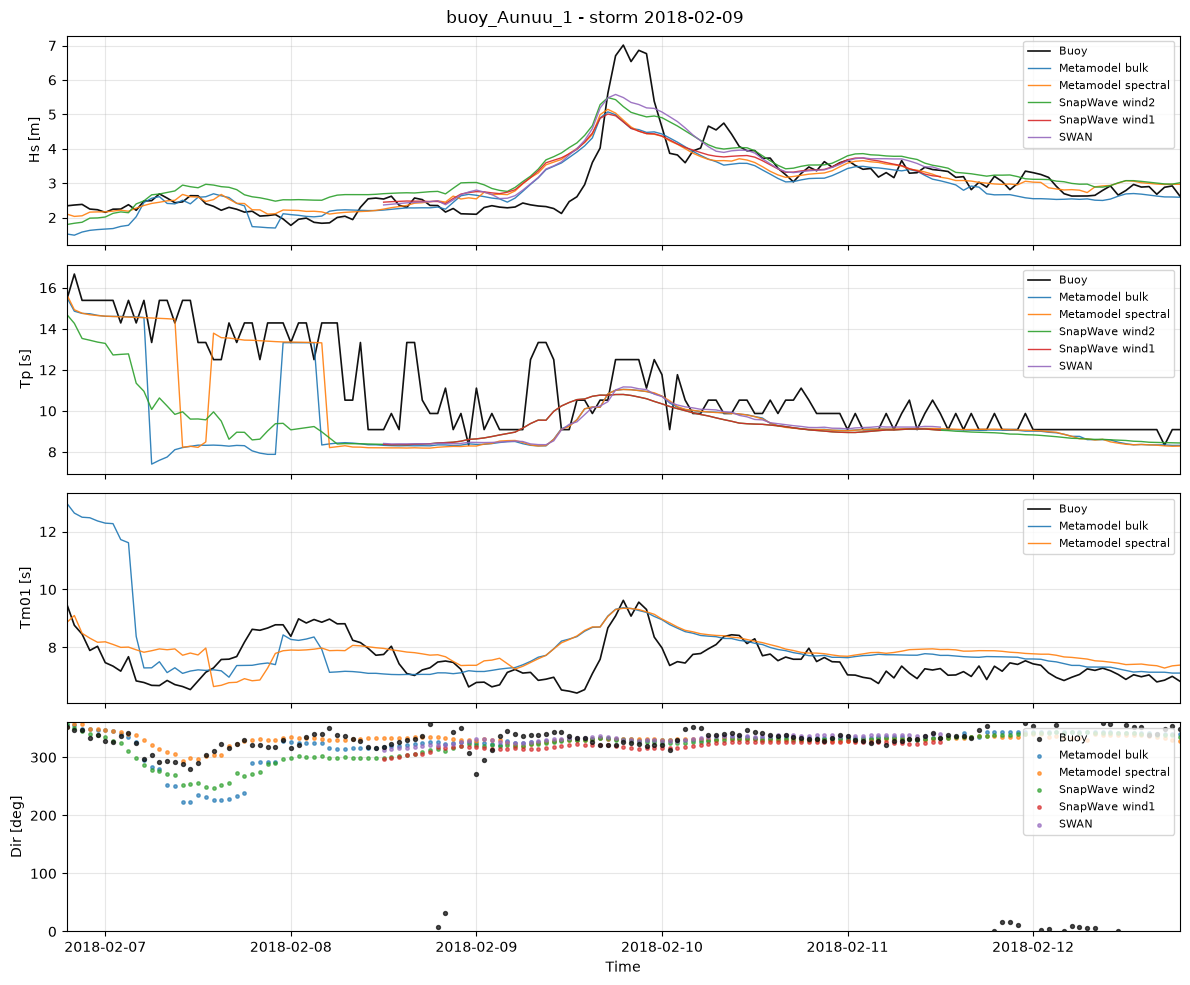

Storm 2018-10-20 18:00, against the buoys: Metamodel bulk, Metamodel spectral, SnapWave wind2
hours every estimate has, per buoy: {'buoy_Aunuu_2': 145}


variable                           hs          tp         dir      
                                 bias  rmse  bias  rmse  bias  rmse
site         estimate                                              
buoy_Aunuu_2 Metamodel bulk     -0.04  0.17  0.21  2.00 -4.16  6.52
             Metamodel spectral  0.03  0.16  0.39  2.29  3.36  6.59
             SnapWave wind2     -0.04  0.18 -0.17  1.71 -4.96  6.98

peak                time  minus Buoy  lag (h)
site         source                                                           
buoy_Aunuu_2 Buoy                3.81 2018-10-20 18:00:00        0.00      0.0
             Metamodel bulk      3.69 2018-10-20 14:00:00       -0.13     -4.0
             Metamodel spectral  3.64 2018-10-20 14:00:00       -0.17     -4.0
             SnapWave wind2      3.73 2018-10-20 14:00:00       -0.09     -4.0

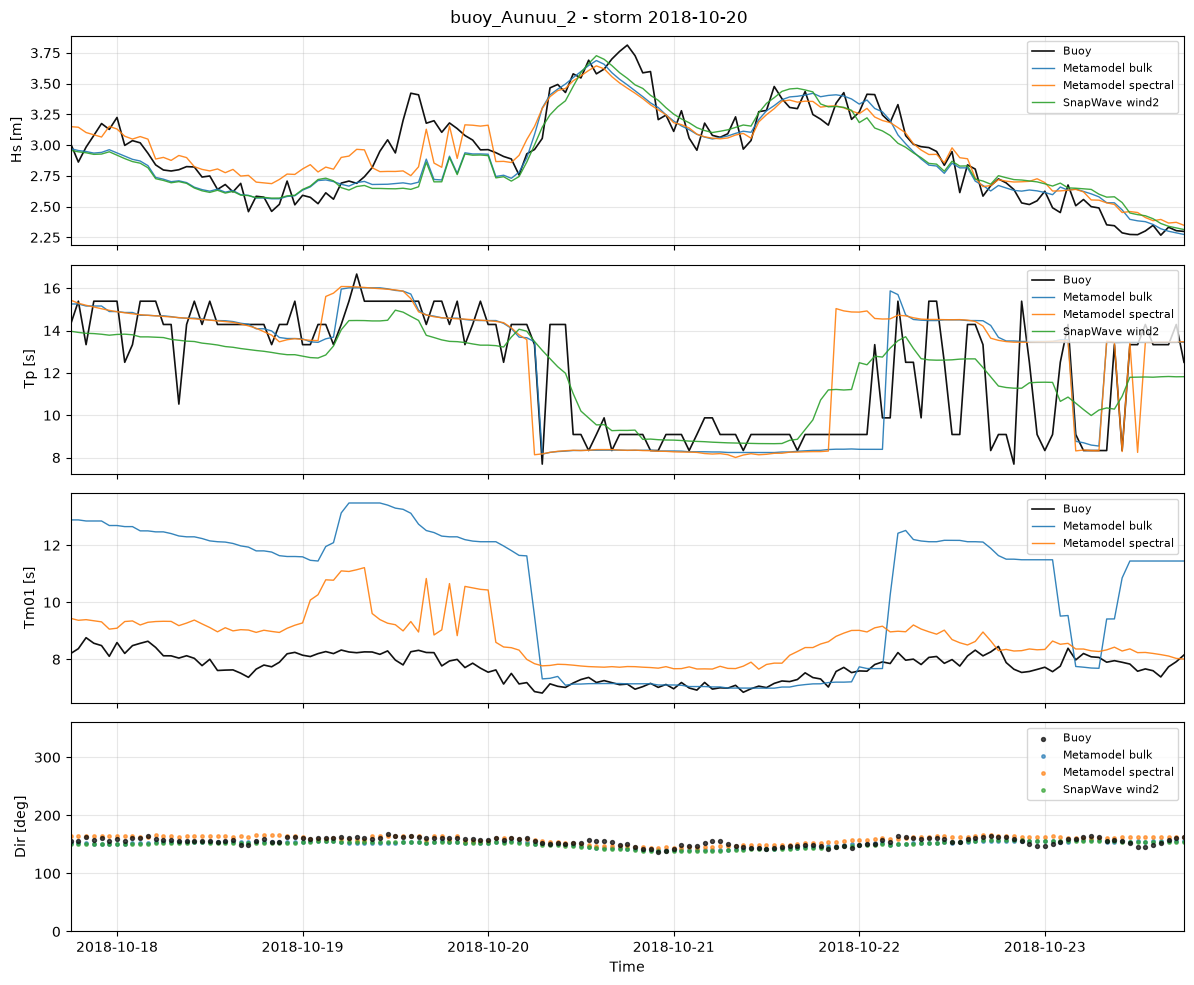

Storm 2018-07-09 09:00, against the buoys: Metamodel bulk, Metamodel spectral, SnapWave wind2
hours every estimate has, per buoy: {'buoy_Aunuu_2': 145}


variable                           hs          tp         dir       
                                 bias  rmse  bias  rmse  bias   rmse
site         estimate                                               
buoy_Aunuu_2 Metamodel bulk     -0.08  0.25  0.36  1.94 -3.77   8.83
             Metamodel spectral -0.07  0.25 -0.05  2.05  3.18  10.08
             SnapWave wind2     -0.08  0.25  0.47  1.76 -4.17   8.82

peak                time  minus Buoy  lag (h)
site         source                                                           
buoy_Aunuu_2 Buoy                3.61 2018-07-08 23:00:00        0.00      0.0
             Metamodel bulk      3.38 2018-07-09 08:00:00       -0.23      9.0
             Metamodel spectral  3.32 2018-07-09 08:00:00       -0.30      9.0
             SnapWave wind2      3.43 2018-07-09 08:00:00       -0.18      9.0

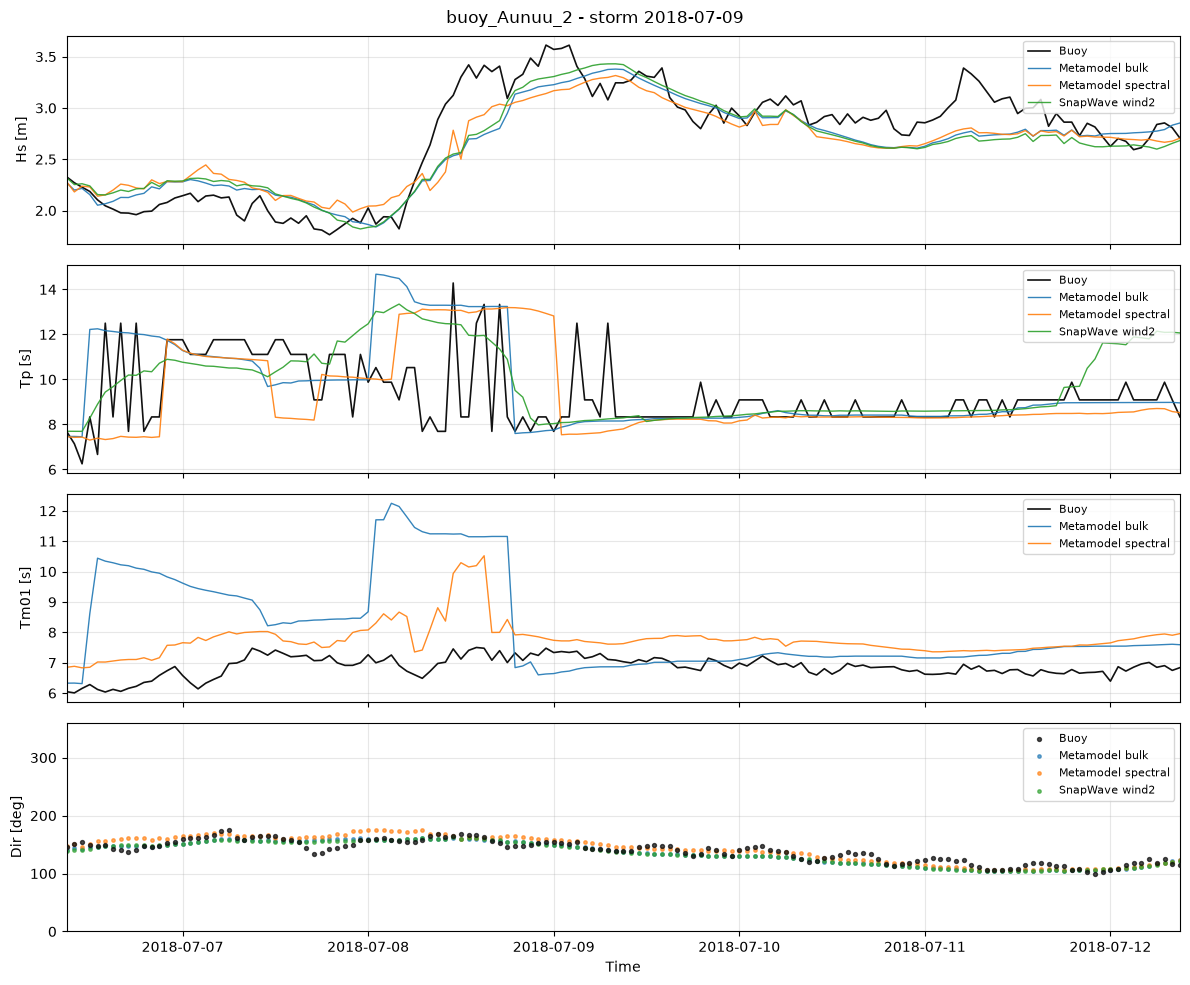

Storm 2018-09-17 21:00, against the buoys: Metamodel bulk, Metamodel spectral, SnapWave wind2
hours every estimate has, per buoy: {'buoy_Aunuu_2': 145}


variable                           hs          tp          dir       
                                 bias  rmse  bias  rmse   bias   rmse
site         estimate                                                
buoy_Aunuu_2 Metamodel bulk      0.04  0.17  0.46  2.43   4.34  13.52
             Metamodel spectral  0.04  0.18 -0.21  2.15  11.30  20.08
             SnapWave wind2      0.00  0.17  0.53  1.89   4.28  13.18

peak                time  minus Buoy  lag (h)
site         source                                                           
buoy_Aunuu_2 Buoy                3.33 2018-09-18 03:00:00        0.00      0.0
             Metamodel bulk      3.27 2018-09-17 21:00:00       -0.06     -6.0
             Metamodel spectral  3.28 2018-09-17 21:00:00       -0.05     -6.0
             SnapWave wind2      3.25 2018-09-17 12:00:00       -0.08    -15.0

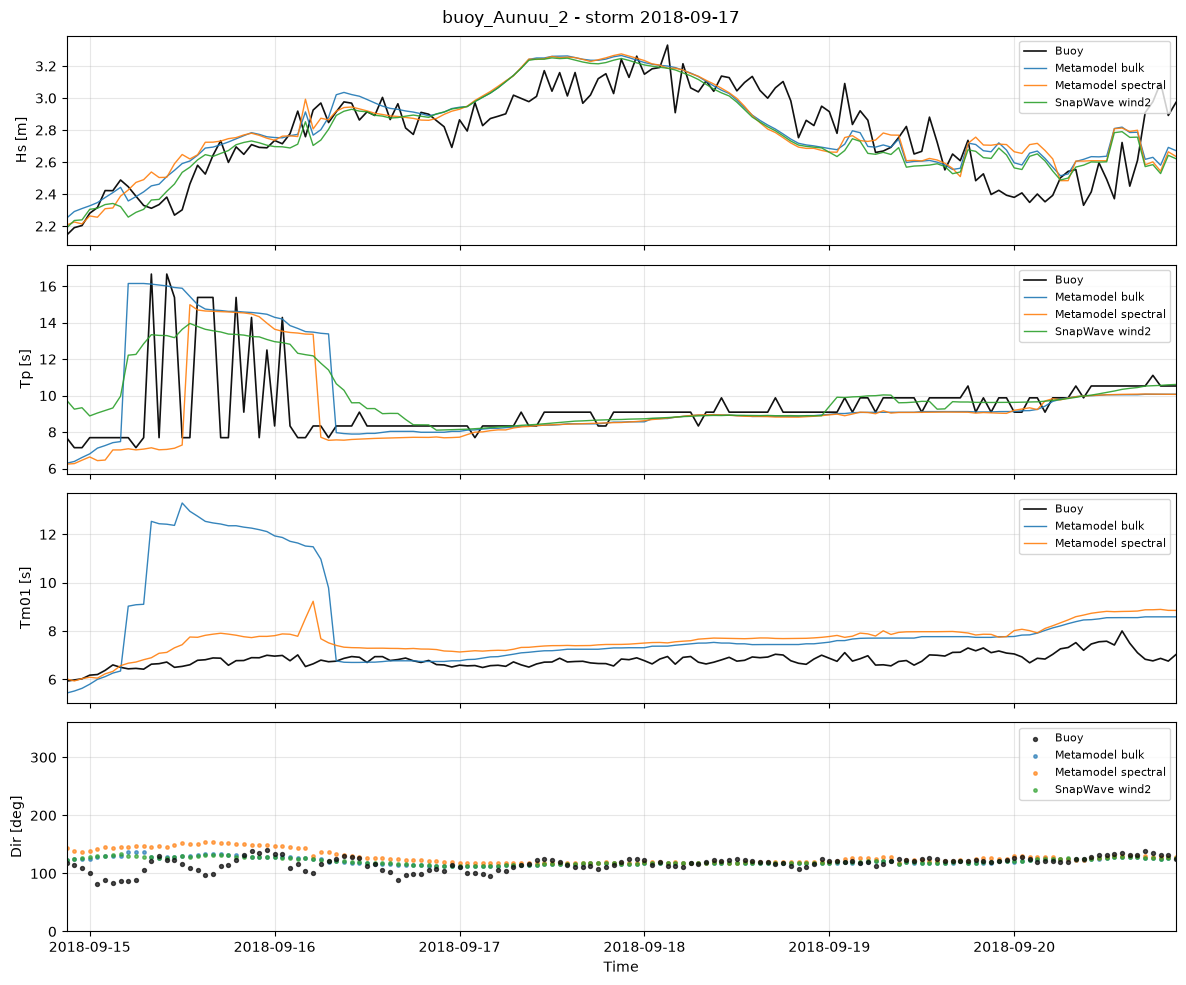

In [ ]:
for storm in storms.itertuples():
    span = slice(storm.peak - window, storm.peak + window)
    obs = buoy.sel(time=span)
    sites = [s for s in obs.sites.values if int(obs["hs"].sel(sites=s).notnull().sum())]
    if not sites:
        print(f"{storm.peak:%Y-%m-%d}: no buoy data")
        continue
    obs = obs.sel(sites=sites)
    present = {
        label: est.sel(sites=sites).reindex(time=obs.time)
        for label, est in estimates.items()
        if est.sel(time=span).sizes["time"]
    }
    print(f"Storm {storm.peak:%Y-%m-%d %H:%M}, against the buoys: {', '.join(present)}")
    metrics = val.common_hours_metrics(obs, present, compare_variables)
    print(
        f"hours every estimate has, per buoy: {metrics.groupby('site')['n'].max().to_dict()}"
    )
    table = metrics.set_index(["site", "estimate", "variable"])[
        ["bias", "rmse"]
    ].unstack("variable")
    columns = [
        (m, v) for v in compare_variables for m in ("bias", "rmse") if (m, v) in table
    ]
    display(
        table[columns]
        .swaplevel(axis=1)
        .reindex(list(present), level="estimate")
        .round(2)
    )
    display(val.event_peaks(obs, present).round(2))
    for site in sites:
        val.plot_buoy_timeseries(obs, present, site, variables=series_variables)
        plt.suptitle(f"{site} - storm {storm.peak:%Y-%m-%d}")
        plt.show()

## 4 · Maps of the storm hour

Hs, then mean direction, of every estimate at the storm's map hour on one colour scale, the
observed buoy values on every panel. Hs: the dynamic runs on the mesh where their map was
saved (else at the sites). Direction: every estimate at the sites (SnapWave maps hold none).
The metamodel at the sites of `map_set` and `buoy_set`.

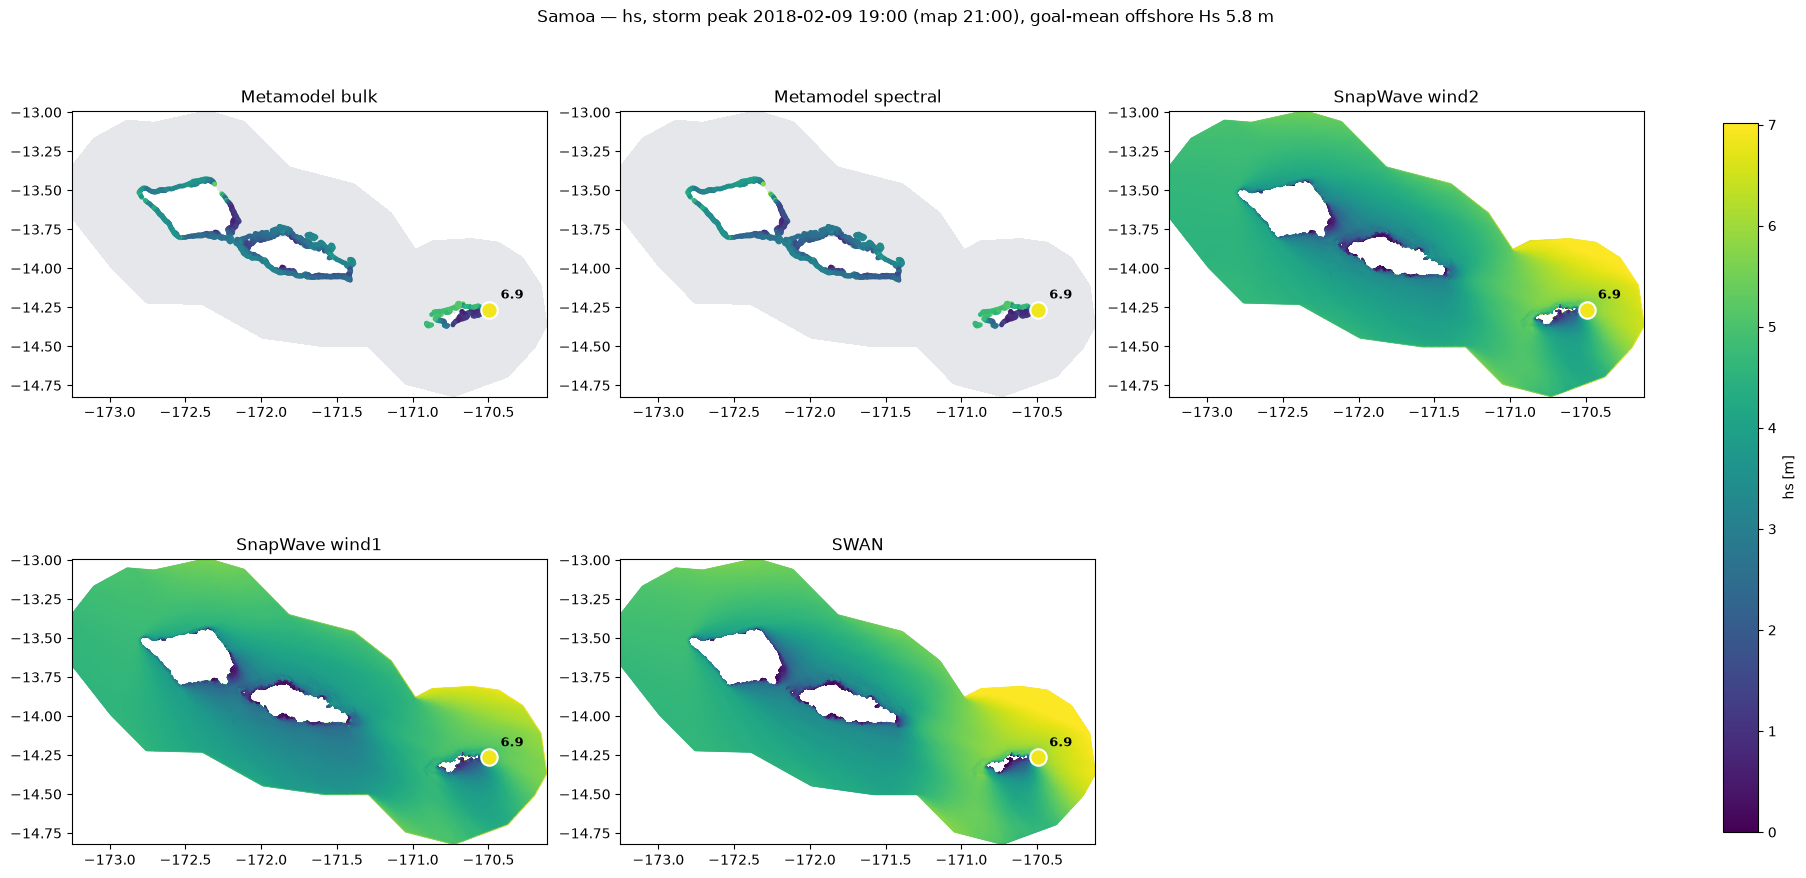

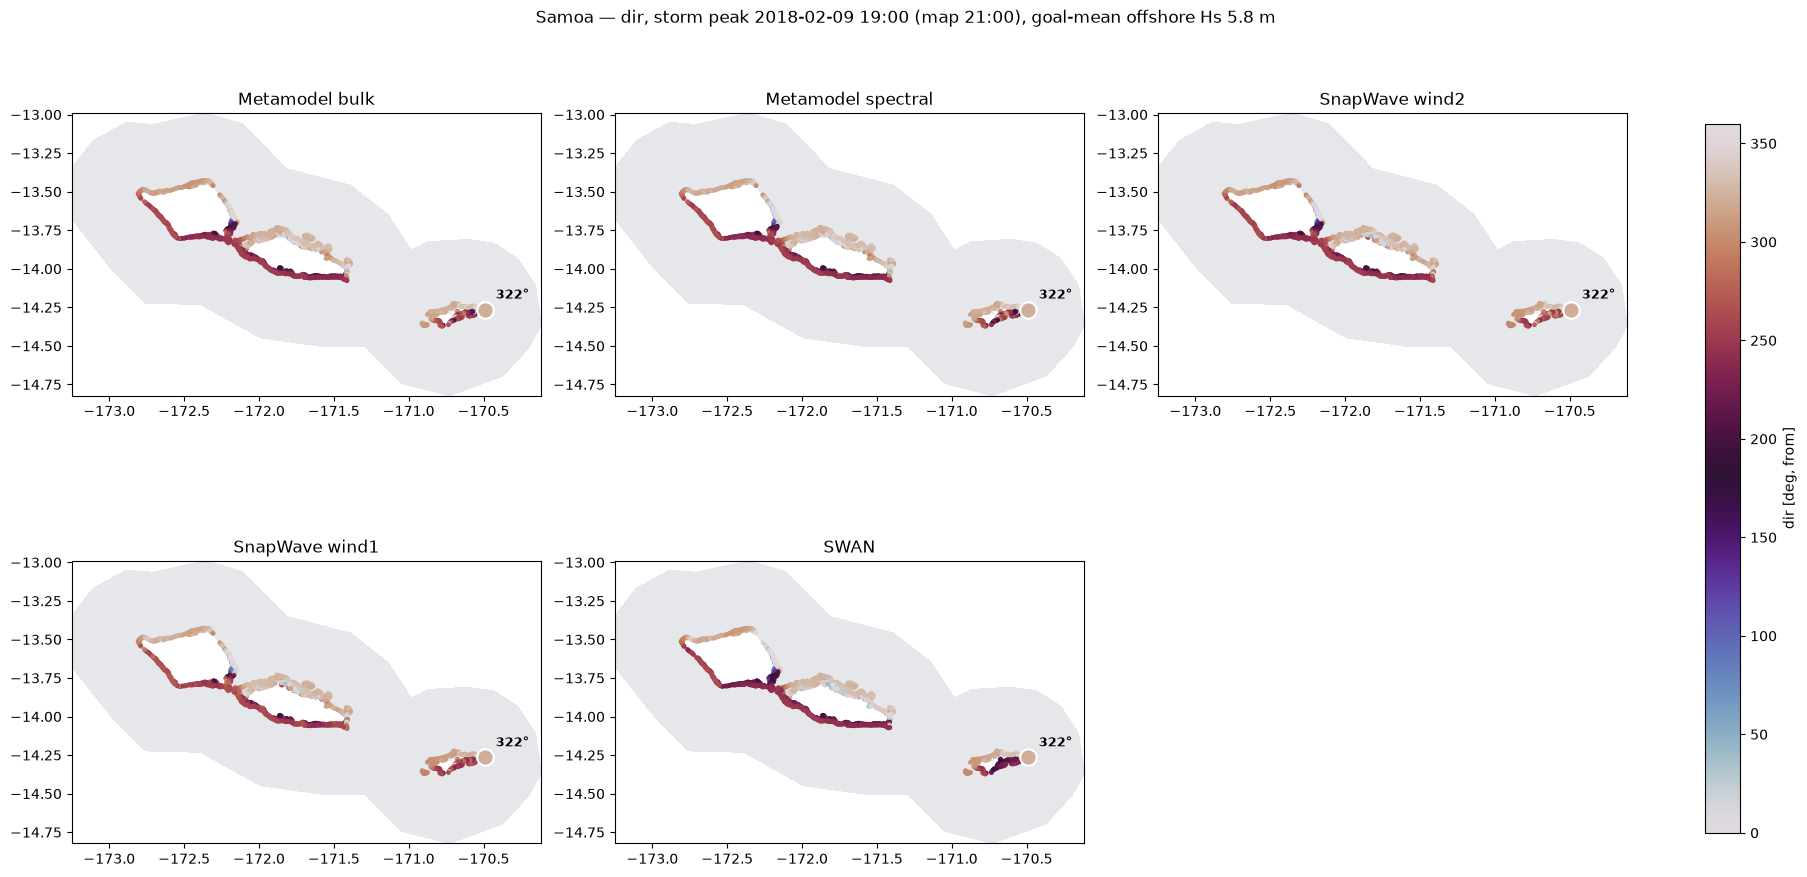

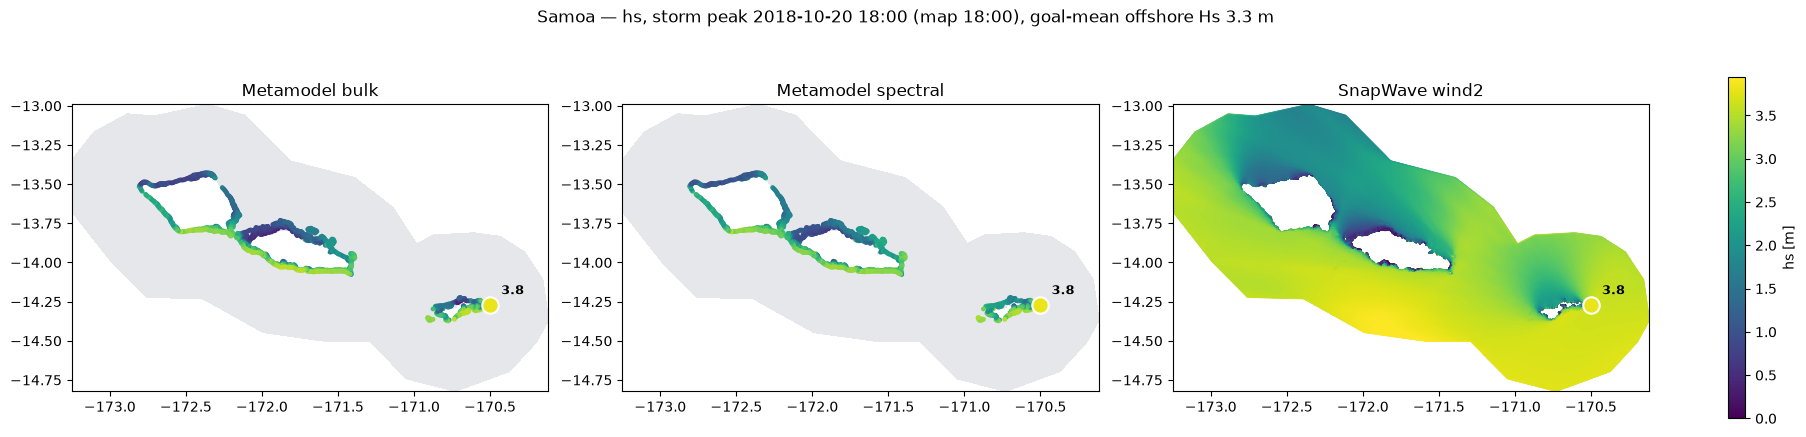

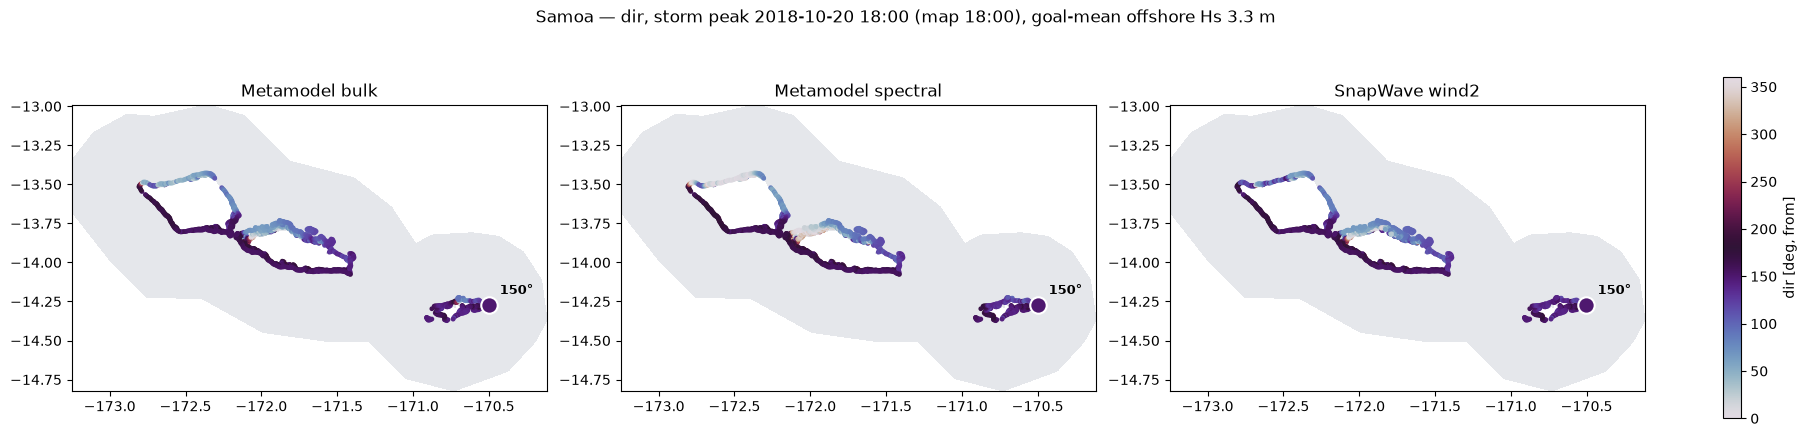

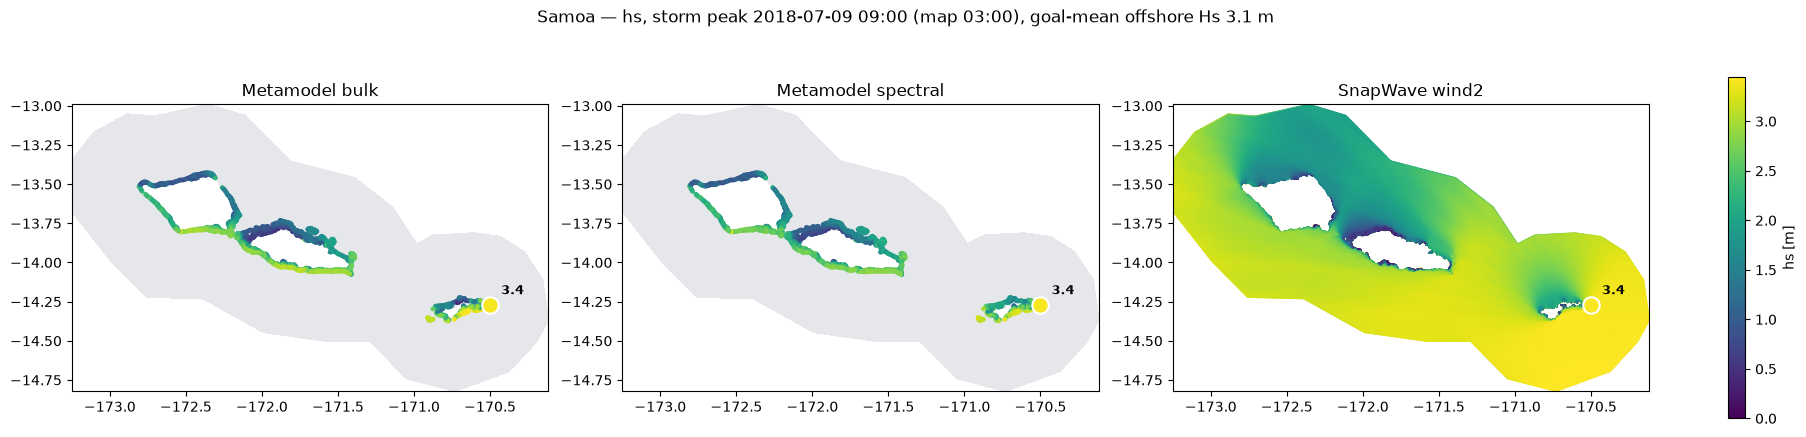

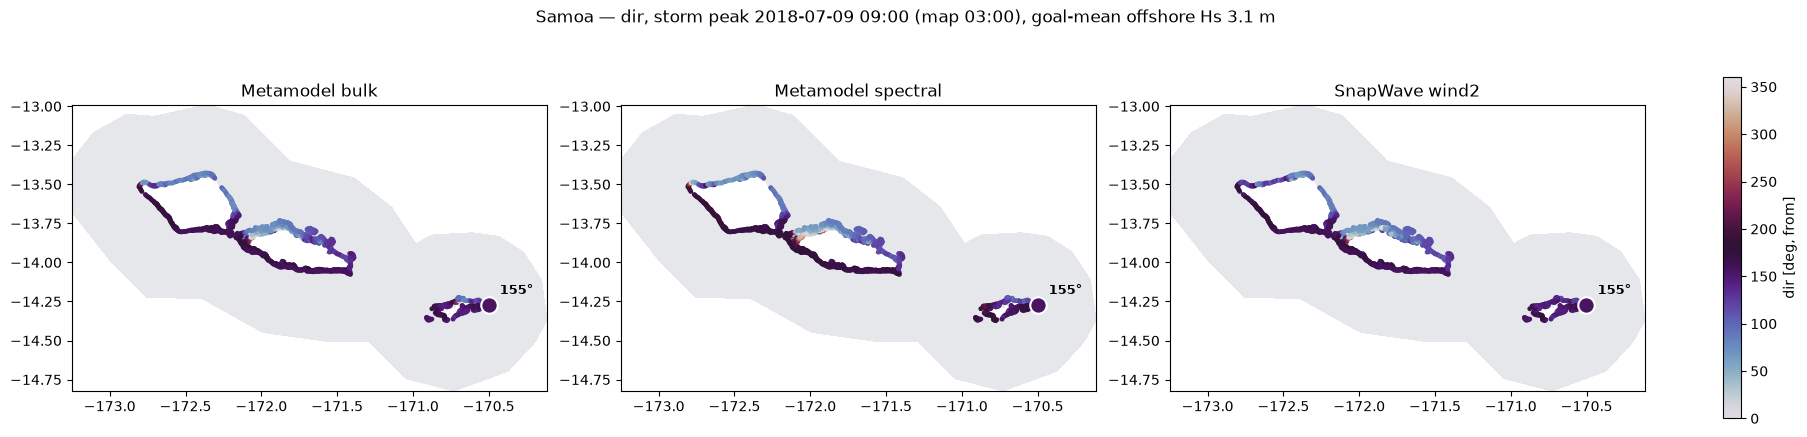

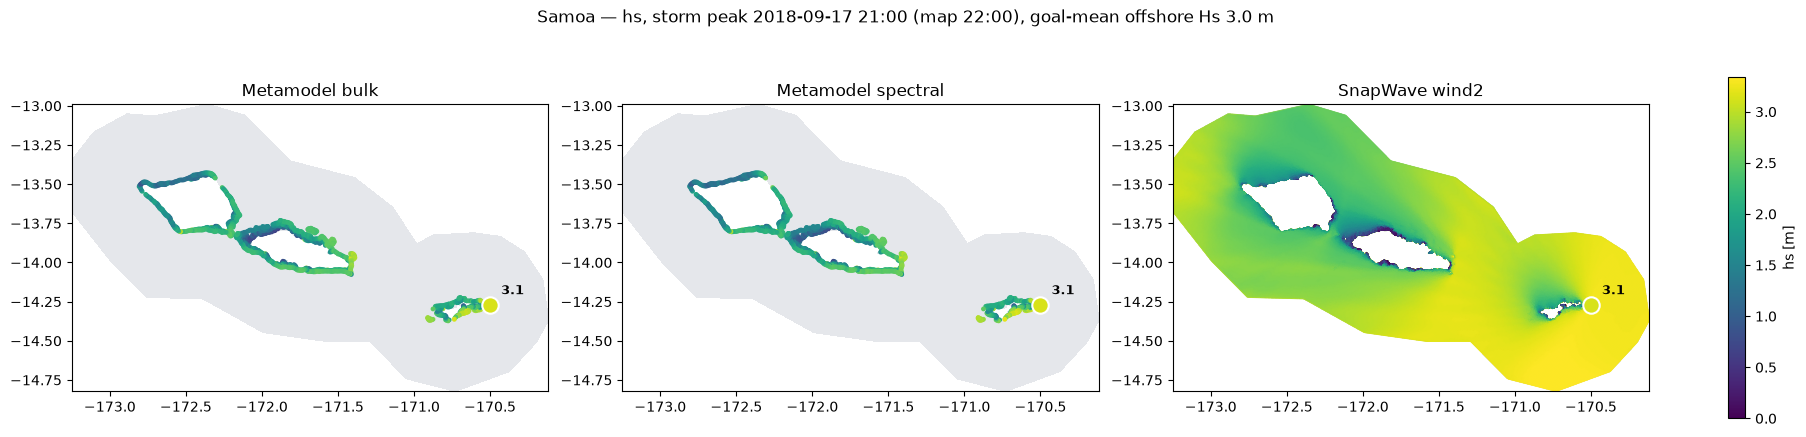

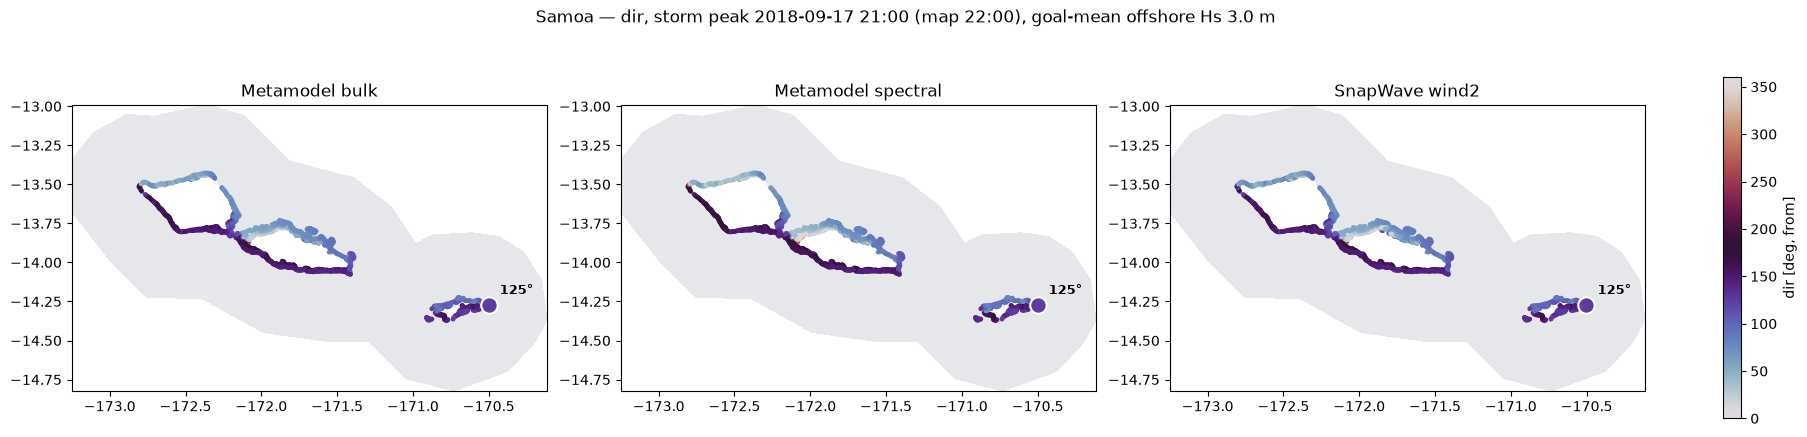

In [ ]:
tri = viz.storm_triangulation(
    paths[first].parent / f"{storms['map_hour'].iloc[0]:%Y%m%d %H%M%S}"
)
for storm in storms.itertuples():
    t = storm.map_hour
    maps = {
        label: sim.load_storm_map(paths[label].parent / f"{t:%Y%m%d %H%M%S}")
        for label in runs
        if t in run_maps[label]
    }
    obs = buoy.sel(time=t) if t in buoy.get_index("time") else None
    for variable in ("hs", "dir"):
        fields = {}
        for label, est in estimates.items():
            if (
                label in maps and variable == "hs"
            ):  # direction at the sites for all (SnapWave maps have none)
                fields[label] = maps[label][variable]
            elif t in est.get_index("time") and bool(
                est[variable].sel(time=t).notnull().any()
            ):
                fields[label] = est[variable].sel(time=t)
        observed = (
            obs[variable].dropna("sites")
            if obs is not None and variable in obs
            else None
        )
        viz.plot_storm_fields(
            fields,
            tri,
            variable,
            observed=observed,
            extent=extent,
            title=f"{variable}, storm peak {storm.peak:%Y-%m-%d %H:%M} (map {t:%H:%M}), "
            f"goal-mean offshore Hs {storm.goal_mean_hs:.1f} m",
        )
        plt.show()

## 5 · Dynamic runs against `reference_run`

The other dynamic runs against the reference (e.g. SnapWave builds against SWAN) on the hours
and sites they share, per site group and variable; then, at the storm map hours the reference
saved, the difference maps: Hs node by node on the mesh, direction at the sites (SnapWave maps
hold no direction). Red: higher than the reference (or turned clockwise).

In [ ]:
if reference_run in runs:
    ref = runs[reference_run]
    rows = [
        val.compare(
            ref, run, variables=[v for v in compare_variables if v in run]
        ).metrics.assign(run=label)
        for label, run in runs.items()
        if label != reference_run
    ]
    for variable, table in pd.concat(rows).groupby("variable", sort=False):
        print(f"{variable}: run - {reference_run}, {ref.sizes['time']} hours")
        display(
            table.pivot_table(
                index="group", columns="run", values=["bias", "rmse", "r2"]
            ).round(3)
        )
else:
    print(f"reference run {reference_run!r} not among {list(runs)}")

hs: run - SWAN, 73 hours


bias                            r2                 \
run             SnapWave wind1 SnapWave wind2 SnapWave wind1 SnapWave wind2   
group                                                                         
10m                     -0.093          0.018          0.578          0.634   
20m                      0.028          0.128          0.685          0.723   
50m                     -0.004          0.129          0.841          0.880   
5m                      -0.221         -0.174          0.325          0.384   
Apia                    -0.204         -0.131          0.918          0.961   
buoy_Aunuu_1            -0.129          0.114          0.889          0.953   
buoy_Aunuu_2            -0.140          0.084          0.908          0.967   
buoy_King_Poloa         -0.361         -0.028          0.692          0.973   

                          rmse                 
run             SnapWave wind1 SnapWave wind2  
group                                          
10m                      0.550          0.513  
20m                      0.547          0.513  
50m                      0.448          0.390  
5m                       0.422          0.403  
Apia                     0.277          0.192  
buoy_Aunuu_1             0.294          0.192  
buoy_Aunuu_2             0.288          0.173  
buoy_King_Poloa          0.451          0.133

tp: run - SWAN, 73 hours


bias                            r2                 \
run             SnapWave wind1 SnapWave wind2 SnapWave wind1 SnapWave wind2   
group                                                                         
10m                      0.014          0.014          0.802          0.802   
20m                      0.075          0.075          0.762          0.762   
50m                      0.116          0.116          0.763          0.763   
5m                      -0.030         -0.030          0.805          0.805   
Apia                     0.048          0.048          0.881          0.881   
buoy_Aunuu_1             0.045          0.045          0.696          0.696   
buoy_Aunuu_2             0.032          0.032          0.696          0.696   
buoy_King_Poloa         -0.009         -0.009          0.932          0.932   

                          rmse                 
run             SnapWave wind1 SnapWave wind2  
group                                          
10m                      0.427          0.427  
20m                      0.456          0.456  
50m                      0.440          0.440  
5m                       0.426          0.426  
Apia                     0.344          0.344  
buoy_Aunuu_1             0.447          0.447  
buoy_Aunuu_2             0.454          0.454  
buoy_King_Poloa          0.212          0.212

dir: run - SWAN, 73 hours


bias                            r2                 \
run             SnapWave wind1 SnapWave wind2 SnapWave wind1 SnapWave wind2   
group                                                                         
10m                      4.218          3.488          0.872          0.885   
20m                      8.024          5.580          0.730          0.765   
50m                      2.647          1.601          0.605          0.620   
5m                       1.205          0.531          0.901          0.919   
Apia                    -7.652         -4.578          0.399          0.541   
buoy_Aunuu_1           -11.850         -6.101         -2.153          0.025   
buoy_Aunuu_2           -12.057         -6.587         -2.481         -0.275   
buoy_King_Poloa         -4.145         -0.348          0.713          0.896   

                          rmse                 
run             SnapWave wind1 SnapWave wind2  
group                                          
10m                     28.713         27.136  
20m                     36.464         34.018  
50m                     32.127         31.517  
5m                      27.458         24.793  
Apia                    19.457         16.998  
buoy_Aunuu_1            12.067          6.709  
buoy_Aunuu_2            12.297          7.443  
buoy_King_Poloa          5.265          3.175

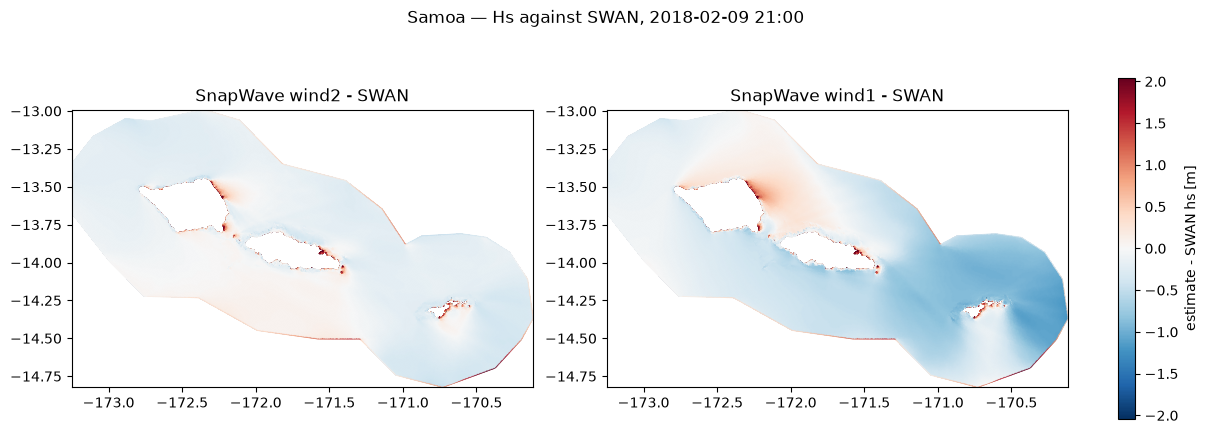

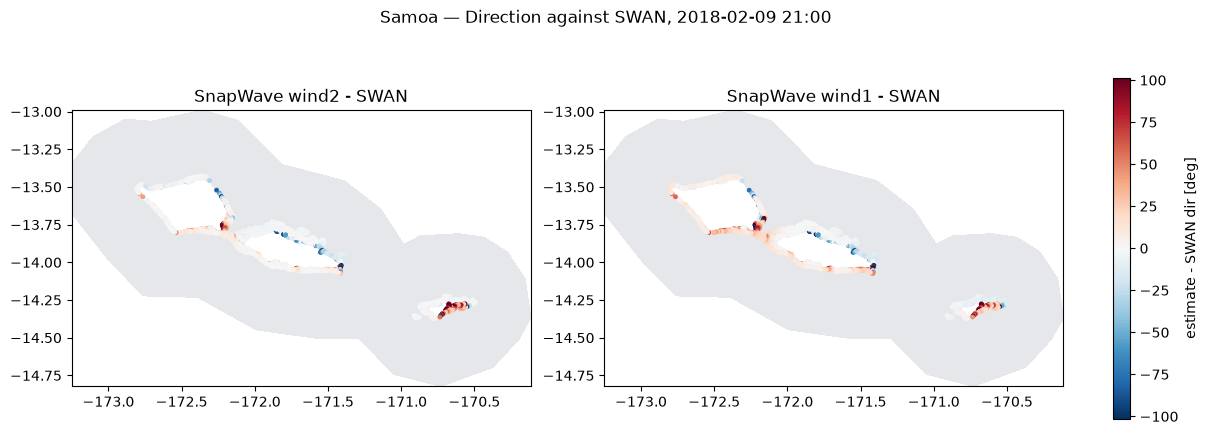

In [ ]:
for storm in storms.itertuples() if reference_run in runs else []:
    t = storm.map_hour
    if t not in run_maps[reference_run]:
        continue
    others = [
        label for label in runs if label != reference_run and t in run_maps[label]
    ]
    ref_map = sim.load_storm_map(paths[reference_run].parent / f"{t:%Y%m%d %H%M%S}")
    hs = {
        label: sim.load_storm_map(paths[label].parent / f"{t:%Y%m%d %H%M%S}")["hs"]
        for label in others
    }
    viz.plot_storm_fields(
        hs,
        tri,
        "hs",
        reference=ref_map["hs"],
        reference_label=reference_run,
        extent=extent,
        ncols=len(hs),
        title=f"Hs against {reference_run}, {t:%Y-%m-%d %H:%M}",
    )
    plt.show()
    direction = {label: runs[label]["dir"].sel(time=t) for label in others}
    viz.plot_storm_fields(
        direction,
        tri,
        "dir",
        reference=runs[reference_run]["dir"].sel(time=t),
        reference_label=reference_run,
        extent=extent,
        ncols=len(direction),
        title=f"Direction against {reference_run}, {t:%Y-%m-%d %H:%M}",
    )
    plt.show()